# 01 - Exploratory Data Analysis (EDA)

**Goal:** every section ends with a _decision_ that feeds a later step (split, `max_len`, or `preprocess`). Anything that does not lead to a decision was removed.

| #   | Section                        | Feeds                                                |
| --- | ------------------------------ | ---------------------------------------------------- |
| 1   | Shape & class balance          | stratified split                                     |
| 2   | Empty / duplicate files        | dataset build (drop duplicates before the split)     |
| 3   | Text lengths                   | `max_len = 512`                                      |
| 4   | Raw samples (`repr`)           | discovering problems by eye                          |
| 5   | Character inventory            | `preprocess` (control chars, NFKC, letter folding)   |
| 6   | Noise presence (% of articles) | `preprocess` (evidence table for the report)         |
| 7   | Attached punctuation           | why punctuation becomes a space, not an empty string |
| 8   | Class leakage                  | limitation for the report / error analysis           |
| 9   | Decision table                 | `src/data/preprocessing.py`                          |


In [1]:
import sys, re, unicodedata
from pathlib import Path
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.config import DATA_DIR, CLASSES
from src.data.loader import load_dataset

FIG_DIR = ROOT / "results" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

df = load_dataset()
df.head(2)

done loading 6500 files for class 'Culture'
done loading 6500 files for class 'Finance'
done loading 6500 files for class 'Medical'
done loading 6500 files for class 'Politics'
done loading 6500 files for class 'Religion'
done loading 6500 files for class 'Sports'
done loading 6500 files for class 'Tech'

Total articles loaded: 45500
done loading 6500 files for class 'Culture'
done loading 6500 files for class 'Finance'
done loading 6500 files for class 'Medical'
done loading 6500 files for class 'Politics'
done loading 6500 files for class 'Religion'
done loading 6500 files for class 'Sports'
done loading 6500 files for class 'Tech'

Total articles loaded: 45500


,text,label
0,القاهرة:عيد عبد الحليمد. سلمان كاصد، ناقد عراق...,Culture
1,نظمت جمعية الإمارات للفنون التشكيلية مساء أمس ...,Culture


## 1. Shape & class balance

_Question: is any class missing or dominant?_


In [2]:
print("shape:", df.shape)
counts = df["label"].value_counts()
print(pd.DataFrame({"count": counts, "%": (counts / len(df) * 100).round(2)}))

shape: (45500, 2)
          count      %
label                 
Culture    6500  14.29
Finance    6500  14.29
Medical    6500  14.29
Politics   6500  14.29
Religion   6500  14.29
Sports     6500  14.29
Tech       6500  14.29


**Decision:** the classes are perfectly balanced, so the split is stratified and the loss needs no class weights.


## 2. Empty and duplicate articles

_Question: are there files to discard, and could a duplicate land in both train and test (data leakage)?_

The loader already skips empty files, so we count the raw `.txt` files and compare with what was loaded.


In [3]:
raw_files = sum(len(list((DATA_DIR / c).glob("*.txt"))) for c in CLASSES)
print("raw .txt files :", raw_files)
print("loaded         :", len(df))
print("skipped (empty):", raw_files - len(df))

dup_mask = df.duplicated(subset="text", keep=False)
print("\narticles involved in duplicates:", dup_mask.sum())
print("extra copies to remove         :", df.duplicated(subset="text").sum())

g = df[dup_mask].groupby("text")["label"].nunique()
print("duplicate groups with conflicting labels:", (g > 1).sum())

raw .txt files : 45500
loaded         : 45500
skipped (empty): 0

articles involved in duplicates: 29
extra copies to remove         : 15
duplicate groups with conflicting labels: 0


**Decision:** drop duplicates (keep the first copy) **before** the split. Executed in `02_preprocessing` / dataset build, never on the original files.


## 3. Text lengths

_Question: is `max_len = 512` reasonable, and how much text do we lose?_


       words    chars
min      2.0     10.0
mean   369.0   2196.0
50%    258.0   1559.0
90%    777.0   4574.0
95%   1105.0   6425.0
99%   1630.0   9555.0
max   5786.0  33339.0

% of articles longer than 512 words: 22.4
           mean  median  truncated_pct
label                                 
Culture   348.2   322.0           17.4
Finance   296.2   223.0           13.9
Medical   246.7   193.0            7.5
Politics  237.7   174.0            7.2
Religion  809.9   704.0           75.7
Sports    295.2   160.0           17.9
Tech      350.6   285.0           17.0


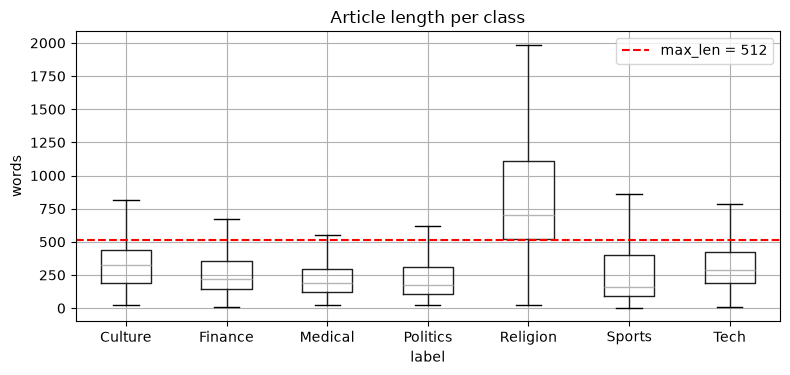

In [4]:
wc = df["text"].map(lambda t: len(t.split()))
cc = df["text"].str.len()
stats = pd.DataFrame({"words": wc.describe(percentiles=[.5, .9, .95, .99]),
                      "chars": cc.describe(percentiles=[.5, .9, .95, .99])}).round(0)
print(stats.loc[["min", "mean", "50%", "90%", "95%", "99%", "max"]])

print("\n% of articles longer than 512 words:", round((wc > 512).mean() * 100, 1))
per_class = (df.assign(wc=wc).groupby("label")["wc"]
               .agg(mean="mean", median="median",
                    truncated_pct=lambda s: (s > 512).mean() * 100).round(1))
print(per_class)

ax = df.assign(wc=wc).boxplot(column="wc", by="label", figsize=(8, 4), showfliers=False)
ax.axhline(512, color="red", ls="--", label="max_len = 512")
ax.set_ylabel("words"); ax.set_title("Article length per class"); plt.suptitle("")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "length_per_class.png", dpi=150, bbox_inches="tight")
plt.show()

**Decision:** `max_len = 512` (as required). The median is far below 512, so most articles are kept whole; Religion is much longer and is truncated the most. Report the exact percentages from the table above.


## 4. Raw samples (read with your own eyes)

_Question: what looks strange?_

`repr()` exposes hidden characters (`\u202e`, `\xa0`, `\u0640`) that `print` hides.


In [5]:
for label in CLASSES:
    sub = df[df["label"] == label].sample(2, random_state=42)
    print(f"\n[{label}]")
    for t in sub["text"]:
        print(" ", repr(t[:300]))


[Culture]
  'يتناول يسري مصطفى في كتابه «أوهام الأصالة»، أحد الموضوعات الأكثر إثارة للجدل، وهو موضوع «النسبية الثقافية»، الذي يجري التعبير عنه في الخطابات الثقافية والسياسية الشائعة بالخصوصية الثقافية، فمنذ بدايات التحديث، ووصولاً إلى ما بات يعرف بعصر العولمة، تتعالى الأصوات المطالبة بحماية الهوية والثوابت الثقا'
  'ضمن فعاليات ايام الشارقة المسرحية عرضت مساء امس الاول في معهد الشارقة للفنون المسرحية، مسرحية الذي نسي أن يموت فكرة وتأليف اسماعيل عبدالله وسينوغرافيا وإخراج حسن رجب.المسرحية قدمها مسرح خورفكان للفنون، وهي من نوع الموونودراما حيث قام ببطولتها الفنان جمعة علي.أول ما يمكن تسجيله بخصوص هذا العرض هوالجر'

[Finance]
  'على ما يبدو أن أسواق المنطقة بدأت الخروج تدريجياً من صدمة الأحداث التي تشهدها الساحة المصرية والتي بدورها تحاول ان تعود تدريجياً لطبيعتها بعد سلسلة الإجراءات الأخيرة التي اتخذتها الحكومة المصرية من إعادة فتح عدد من المصارف والمصانع وغير ذلك من المنشآت الحيوية، حيث ارتفعت أسواق المنطقة بشكل شبه جماعي'
  'نجحت 5 بورصات خليجية في الارتفاع هذا الأسبوع يتصدرها سوق دبي

**Observations to confirm in the output above** (write your own if you see others):

- tanween and other diacritics (`أيضاً`, `دوراً`)
- Arabic comma used as a decimal separator (`0،14%`, `105،2`)
- sentence-final dot glued to the next word (`.وقال`, `صفقة .وشهدت`)
- some words glued together in the source (`الضغوطالبيعية`, `تداول54،3`)
- guillemets `« »` around names


## 5. Character inventory

_Question: which characters exist that we did not expect?_

Counting every character with its Unicode name is how we found hidden direction marks, presentation forms and Persian letters.


In [6]:
char_counts = Counter()
for t in df["text"]:
    char_counts.update(t)
print("distinct characters:", len(char_counts))

def is_plain(ch):
    o = ord(ch)
    return (0x0621 <= o <= 0x064A) or ch.isascii() and (ch.isalnum() or ch == " ")

rows = [(ch, f"U+{ord(ch):04X}", unicodedata.name(ch, "?"), n)
        for ch, n in char_counts.most_common() if not is_plain(ch)]
inv = pd.DataFrame(rows, columns=["char", "code", "name", "count"])
inv["char"] = inv["char"].map(repr)
inv.head(40)

distinct characters: 270


,char,code,name,count
0,'،',U+060C,ARABIC COMMA,979526
1,'.',U+002E,FULL STOP,615877
2,'ً',U+064B,ARABIC FATHATAN,306667
3,':',U+003A,COLON,129916
4,'\u202c',U+202C,POP DIRECTIONAL FORMATTING,119691
5,'\u202e',U+202E,RIGHT-TO-LEFT OVERRIDE,118439
6,'َ',U+064E,ARABIC FATHA,91128
7,'«',U+00AB,LEFT-POINTING DOUBLE ANGLE QUOTATION MARK,72216
8,'»',U+00BB,RIGHT-POINTING DOUBLE ANGLE QUOTATION MARK,71505
9,')',U+0029,RIGHT PARENTHESIS,66965


Persian/Urdu letters        339
Presentation forms          463
Arabic-Indic digits        1659
Tatweel                    5527
Direction/zero-width     241873
Diacritics               572933
Arabic punctuation      1009018
dtype: int64


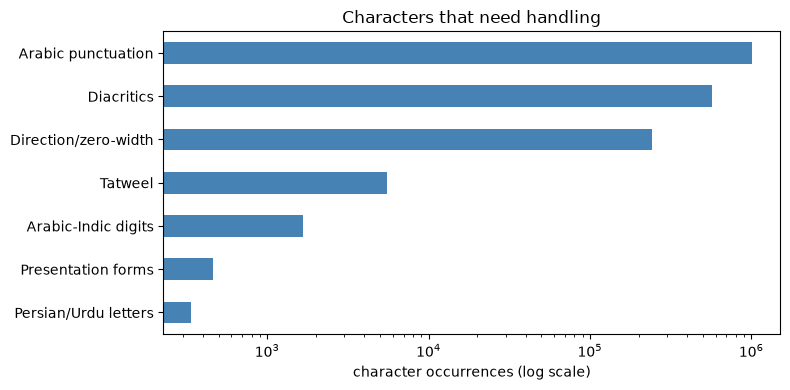

In [7]:
GROUPS = {
    "Diacritics":            [(0x064B, 0x0652), (0x0670, 0x0670)],
    "Tatweel":               [(0x0640, 0x0640)],
    "Direction/zero-width":  [(0x200B, 0x200F), (0x202A, 0x202E), (0x2066, 0x2069), (0xFEFF, 0xFEFF)],
    "Arabic-Indic digits":   [(0x0660, 0x0669)],
    "Presentation forms":    [(0xFB50, 0xFDFF), (0xFE70, 0xFEFF)],
    "Persian/Urdu letters":  [(0x067E, 0x06D3)],
    "Arabic punctuation":    [(0x060C, 0x060C), (0x061B, 0x061B), (0x061F, 0x061F), (0x066A, 0x066D)],
}
def group_total(ranges):
    return sum(n for ch, n in char_counts.items()
               if any(lo <= ord(ch) <= hi for lo, hi in ranges))

grp = pd.Series({k: group_total(v) for k, v in GROUPS.items()}).sort_values()
print(grp)

ax = grp.plot.barh(figsize=(8, 4), color="steelblue", logx=True)
ax.set_xlabel("character occurrences (log scale)")
ax.set_title("Characters that need handling")
plt.tight_layout()
plt.savefig(FIG_DIR / "char_groups.png", dpi=150, bbox_inches="tight")
plt.show()

**Decisions:**

- strip direction / zero-width characters (frequent and invisible)
- `unicodedata.normalize("NFKC", ...)` first, to convert presentation forms to normal letters
- fold `ی → ي` and `ک → ك`
- remove diacritics and tatweel; convert Arabic-Indic digits to ASCII


## 6. Noise presence (% of articles)

_Question: how widespread is each problem?_

This is the **quantitative evidence** for each cleaning rule. We use Python's `re` with `.map` because `.str.contains` (pyarrow) cannot parse `\uXXXX` in patterns.


Teh marbuta               99.93
Alef variants             99.83
Alef maqsura              97.75
Diacritics                86.66
Latin letters             12.76
Decimal comma (0،14)       5.18
Direction / zero-width     3.83
Mentions / hashtags        3.28
Emails                     1.79
Tatweel                    1.21
URLs                       0.41
Repeated Arabic letter     0.39
Arabic-Indic digits        0.38
Persian letters            0.09
Presentation forms         0.05
HTML tags                  0.00
dtype: float64


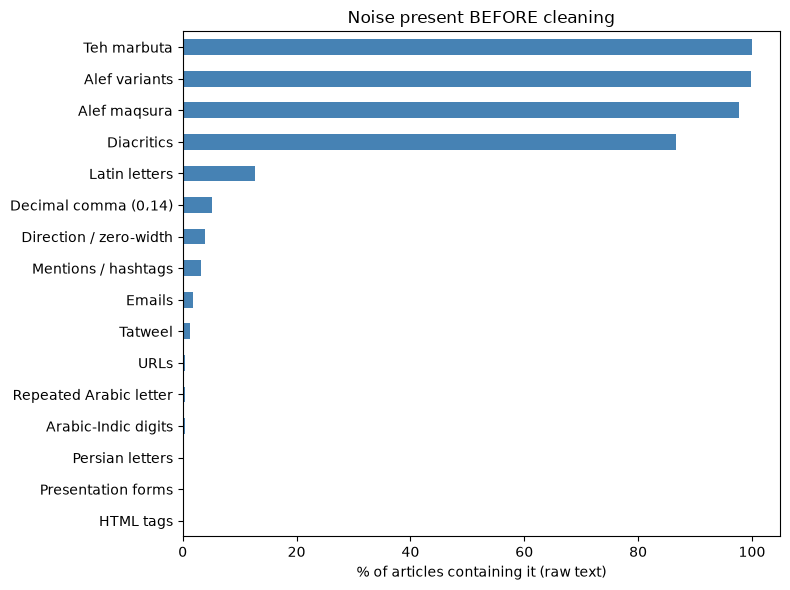

In [8]:
NOISE = {
    "HTML tags":              r"<[^>]+>",
    "URLs":                   r"https?://\S+|www\.\S+",
    "Emails":                 r"[\w\.-]+@[\w\.-]+\.\w+",
    "Mentions / hashtags":    r"[@#]\w+",
    "Diacritics":             r"[\u064B-\u0652\u0670]",
    "Tatweel":                r"\u0640",
    "Direction / zero-width": r"[\u200b-\u200f\u202a-\u202e\u2066-\u2069\ufeff]",
    "Arabic-Indic digits":    r"[\u0660-\u0669]",
    "Presentation forms":     r"[\uFB50-\uFDFF\uFE70-\uFEFF]",
    "Persian letters":        r"[\u06CC\u06A9]",
    "Alef variants":          "[أإآٱ]",
    "Alef maqsura":           "ى",
    "Teh marbuta":            "ة",
    "Latin letters":          r"[A-Za-z]",
    "Decimal comma (0،14)":   r"(?<=\d)،(?=\d)",
    "Repeated Arabic letter": r"([\u0621-\u064A])\1{2,}",
}
presence = {name: df["text"].map(lambda t, rx=re.compile(p): rx.search(t) is not None).mean() * 100
            for name, p in NOISE.items()}
pres = pd.Series(presence).sort_values()
print(pres.round(2).sort_values(ascending=False))

ax = pres.plot.barh(figsize=(8, 6), color="steelblue")
ax.set_xlabel("% of articles containing it (raw text)")
ax.set_title("Noise present BEFORE cleaning")
plt.tight_layout()
plt.savefig(FIG_DIR / "noise_before.png", dpi=150, bbox_inches="tight")
plt.show()

In [9]:
# Why are Emails (1.8%) more common than URLs (0.4%)? Look at real matches.
rx = re.compile(r"[\w\.-]+@[\w\.-]+\.\w+")
shown = 0
for t in df["text"]:
    m = rx.search(t)
    if m:
        s = max(0, m.start() - 25)
        print(repr(t[s:m.end() + 25]))
        shown += 1
        if shown == 5:
            break

' عاطل عن العمل مستقبلاً. basema.younes@gmail.com'
'م اللعبة الفنية المسرحية .Ohasan005@yahoo.com'
'حريرها ليقول المثقف يريد .Abd.abubaker@hotmail.com'
' تفاصيل شبح الموت الرهيب .elyousef@gmail.com'
'ك بالقارئ إلى بعض الملل. dah_tah@yahoo.fr'


**Decisions:** rules with high percentages are essential; rules with tiny percentages (HTML, URLs, mentions) are kept because they cost nothing, but the report states honestly that they are rare. A repeated-letter rule is **not** added if the percentage above is very small.


## 7. Attached punctuation

_Question: why must punctuation become a **space** and not an empty string?_


In [10]:
sample = df["text"].sample(3000, random_state=42)
toks = [w for t in sample for w in t.split()]
has_ar  = re.compile(r"[\u0621-\u064A]")
has_bad = re.compile(r"[^\u0621-\u064A\u064B-\u0652]")
attached = [w for w in toks if has_ar.search(w) and has_bad.search(w)]
print(f"{len(attached) / len(toks) * 100:.1f}% of raw tokens carry attached non-letter characters")
print(Counter(attached).most_common(15))

raw_vocab = Counter(w for t in df["text"] for w in t.split())
for w in ["درهم", "درهم،", "أمس", "أمس،"]:
    print(w, raw_vocab[w])

10.5% of raw tokens carry attached non-letter characters
[('درهم،', 1063), ('في\u202e', 845), ('.وقال', 576), ('قال:', 546), ('أمس،', 378), ('تعالى:', 349), ('الله،', 345), ('دبي،', 310), ('ذلك،', 262), ('.وفي', 258), ('وسلم:', 241), ('د.', 219), ('نقطة،', 211), ('الإمارات،', 207), ('الدولة،', 206)]
درهم 43187
درهم، 19242
أمس 11643
أمس، 5557


**Decision:** the same word appears as `درهم` and `درهم،` (two vocabulary entries). Replacing punctuation with a space also splits glued cases like `.وقال → وقال` and `القاهرة:عيد → القاهرة عيد`.


## 8. Class leakage (trivial features)

_Question: do article openings reveal the class directly?_


In [11]:
first = df["text"].map(lambda t: " ".join(t.split()[:5]))
for label in CLASSES:
    top = first[df["label"] == label].value_counts().head(3)
    print(f"\n[{label}]")
    for s, n in top.items():
        print(f"   {n:4d} x {s}")


[Culture]
     50 x الشارقة - محمد ولد محمد
     18 x ينظم بيت الشعر في الشارقة
     18 x الشارقة - محمد أبو عرب:

[Finance]
    403 x شهد سوق دبي المالي تداولات
    217 x انخفض مؤشر سوق الإمارات المالي
    202 x ارتفع مؤشر سوق الإمارات المالي

[Medical]
    153 x دبي: إيمان عبدالله آل علي
     89 x دبي: إيمان عبد الله آل
     20 x رأس الخيمة - عدنان عكاشة:

[Politics]
      5 x بحث العاهل السعودي الملك عبدالله
      4 x بحث رئيس الوزراء العراقي نوري
      4 x أعلن المرصد السوري لحقوق الإنسان

[Religion]
    149 x مع حركة الحياة تتوالد الأسئلة
     36 x فاسألوا أهل الذكر إن كنتم
     26 x يتميز الإنسان عن باقي المخلوقات

[Sports]
     12 x أعلن الاتحاد الدولي لكرة القدم
      6 x أعلن الاتحاد الألماني لكرة القدم
      6 x ذكرت تقارير صحافية أن نادي

[Tech]
     14 x أبوظبي - "الخليج":أعلنت مؤسسة الإمارات
     12 x أعلنت مؤسسة الإمارات للاتصالات اتصالات
     10 x أعلنت دو مزود خدمات الاتصالات


**Observation:** journalist bylines and templated openings repeat inside one class (e.g. a Finance market report opening, a Medical byline). This is genuine leakage.

**Decision:** keep the text unchanged (the brief asks for headline + paragraphs) and state it as a **limitation** in the report. High accuracy partly reflects source-specific style; check it in the error analysis.


## 9. Decision table (goes to the report, Chapter 2)

| Observation                                    | Evidence      | Decision                              |
| ---------------------------------------------- | ------------- | ------------------------------------- |
| Perfectly balanced classes                     | Section 1     | stratified split, no class weights    |
| 15 duplicate articles                          | Section 2     | drop before the split (avoid leakage) |
| Median ≈ 258 words, mean ≈ 369, Religion ≈ 810 | Section 3     | `max_len = 512`, report % truncated   |
| Diacritics (tanween etc.)                      | Sections 5-6  | remove                                |
| Hidden direction marks (`\u202e`, ...)         | Sections 5-6  | remove (unexpected finding)           |
| Presentation forms, Persian letters            | Section 5     | NFKC + `ی→ي`, `ک→ك`                   |
| Alef variants, ى, ة                            | Section 6     | fold `أإآٱ→ا`, `ى→ي`, `ة→ه`           |
| Arabic-Indic digits                            | Section 6     | convert to ASCII                      |
| Arabic comma as decimal (`0،14`)               | Sections 4, 6 | convert to `.` between digits         |
| Punctuation attached to words                  | Section 7     | replace with a space                  |
| URLs, emails, mentions, HTML                   | Section 6     | remove (cheap, but rare)              |
| Latin words                                    | Section 6     | keep, lowercase                       |
| Class-revealing bylines                        | Section 8     | keep, report as limitation            |

**Deliberately not done:** stopword removal and stemming (a BiLSTM with fastText vectors uses context and morphology), and repeated-letter collapsing (news text; confirm with the Section 6 percentage).

**Moved out of the EDA:** per-class top keywords. They are computed _after_ `preprocess` in `02_preprocessing`, otherwise `درهم` and `درهم،` are counted separately.
